<a href="https://colab.research.google.com/github/night-marionette/Pneumonia-Triage/blob/main/01_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os
OUT_DIR = '/content/drive/MyDrive/PneumoniaTriage'
os.makedirs(OUT_DIR, exist_ok=True)
print("Folder ready:", OUT_DIR)

Folder ready: /content/drive/MyDrive/PneumoniaTriage


In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [9]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import pandas as pd

# 1. FIX THE SEED (So Golova's numbers never change)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed(42)

# 2. SETUP PATHS
DATA_DIR = '/kaggle/input/chest-xray-pneumonia/chest_xray'
OUT_DIR = '/content/drive/MyDrive/PneumoniaTriage'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Looking for data in:", DATA_DIR)
print("Found folders:", os.listdir(DATA_DIR)) # Should say ['test', 'train', 'val']

# 3. TRANSFORMS (ResNet needs 224x224 and 3 channels)
train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
test_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

# 4. LOAD DATA
full_train = datasets.ImageFolder(f'{DATA_DIR}/train', transform=train_tf)
test_ds = datasets.ImageFolder(f'{DATA_DIR}/test', transform=test_tf)

# The Kaggle val folder only has 16 images, so we split the train folder instead
n_val = int(0.15 * len(full_train))
n_tr = len(full_train) - n_val
train_ds, val_ds = random_split(full_train, [n_tr, n_val], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

print(f"Class mapping: {full_train.classes}") # ['NORMAL', 'PNEUMONIA']
print(f"Images -> Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

# 5. LOAD RESNET-18 (Pretrained)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 6. TRAIN
print("\nStarting training (this will take 5-10 minutes)...")
for epoch in range(3):
    model.train()
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Validation
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Epoch {epoch+1}/3 | Loss: {running_loss/len(train_loader):.3f} | Val Acc: {100 * correct / total:.1f}%")

# 7. GENERATE FINAL TEST_SCORES.CSV FOR GOLOVA
print("\nGenerating final test scores...")
model.eval()
all_scores = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)[:, 1] # Probability of Pneumonia
        all_scores.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

df = pd.DataFrame({
    "id": range(len(all_labels)),
    "true_label": all_labels,
    "score": all_scores
})

save_path = f'{OUT_DIR}/test_scores.csv'
df.to_csv(save_path, index=False)
print(f"SUCCESS! Saved {len(df)} rows to {save_path}")

Looking for data in: /kaggle/input/chest-xray-pneumonia/chest_xray
Found folders: ['chest_xray', '__MACOSX', 'val', 'test', 'train']
Class mapping: ['NORMAL', 'PNEUMONIA']
Images -> Train: 4434 | Val: 782 | Test: 624
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 212MB/s]



Starting training (this will take 5-10 minutes)...
Epoch 1/3 | Loss: 0.096 | Val Acc: 98.0%
Epoch 2/3 | Loss: 0.038 | Val Acc: 98.3%
Epoch 3/3 | Loss: 0.024 | Val Acc: 98.8%

Generating final test scores...
SUCCESS! Saved 624 rows to /content/drive/MyDrive/PneumoniaTriage/test_scores.csv


=== BASELINE (Always guess Pneumonia) ===
Accuracy: 62.5%

=== NEW RESNET-18 MODEL ===
Accuracy: 80.6%
Pneumonia recall (sick kids caught): 99.5% | Missed (False Negatives): 2
False alarms (healthy kids flagged): 119

Showing 2 missed pneumonia cases...


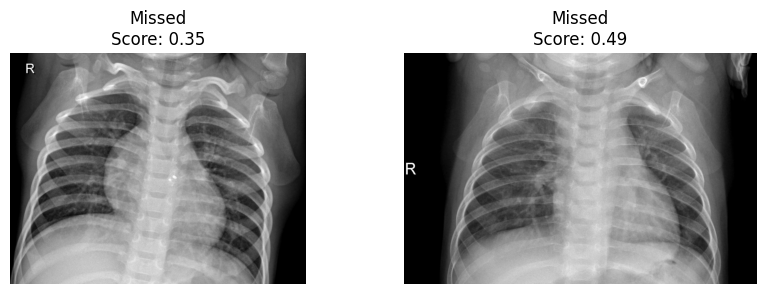

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# FIX: Convert lists to numpy arrays so the math works
labels_array = np.array(all_labels)
scores_array = np.array(all_scores)
preds = (scores_array >= 0.5).astype(int)

print("=== BASELINE (Always guess Pneumonia) ===")
base_preds = np.ones_like(labels_array)
print(f"Accuracy: {(base_preds == labels_array).mean()*100:.1f}%")

print("\n=== NEW RESNET-18 MODEL ===")
print(f"Accuracy: {(preds == labels_array).mean()*100:.1f}%")

tp = ((preds==1) & (labels_array==1)).sum()
fn = ((preds==0) & (labels_array==1)).sum()
fp = ((preds==1) & (labels_array==0)).sum()
tn = ((preds==0) & (labels_array==0)).sum()

print(f"Pneumonia recall (sick kids caught): {tp / (tp + fn)*100:.1f}% | Missed (False Negatives): {fn}")
print(f"False alarms (healthy kids flagged): {fp}")

# 2. Show 3 Missed Cases
miss_idx = np.where((labels_array==1) & (preds==0))[0]
print(f"\nShowing {min(3, len(miss_idx))} missed pneumonia cases...")

if len(miss_idx) > 0:
    fig, axes = plt.subplots(1, min(3, len(miss_idx)), figsize=(10, 3))
    if len(miss_idx) == 1: axes = [axes] # handle 1 case

    for i, ax in enumerate(axes):
        idx = miss_idx[i]
        img_path = test_ds.samples[idx][0]
        score = scores_array[idx]

        ax.imshow(Image.open(img_path).convert("L"), cmap="gray")
        ax.set_title(f"Missed\nScore: {score:.2f}")
        ax.axis("off")
    plt.show()

In [11]:
!pip install grad-cam -q
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from PIL import Image

# 1. Tell Grad-CAM to look at the last layer of our ResNet model
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


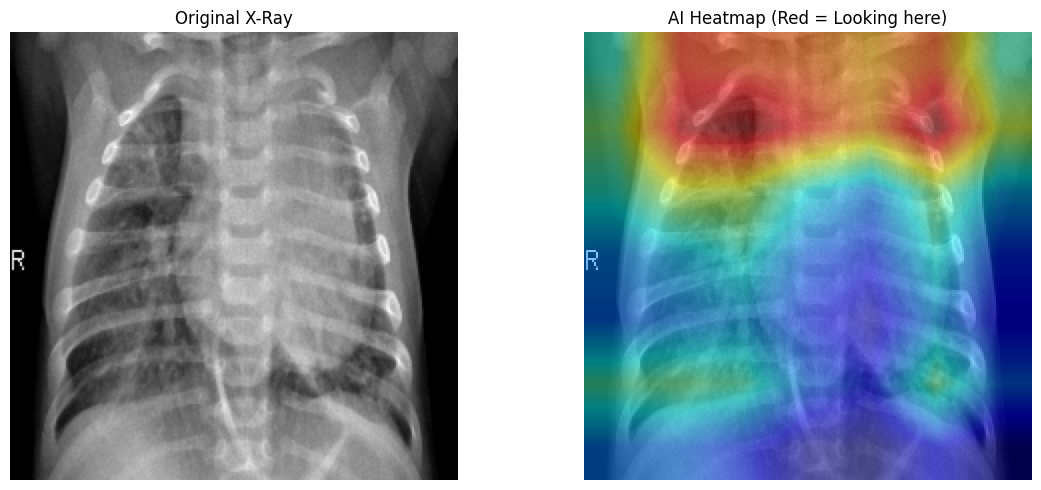

In [12]:
# 1. Find an image in the test set that ACTUALLY has pneumonia
labels_array = np.array(all_labels)
pneumonia_idx = np.where(labels_array == 1)[0][0] # Grabs the first sick patient
img_path = test_ds.samples[pneumonia_idx][0]

# 2. Prepare the image for the model
raw_img = cv2.imread(img_path)
raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
rgb_img = cv2.resize(raw_img, (224, 224))
rgb_img_float = np.float32(rgb_img) / 255

input_tensor = test_tf(Image.open(img_path).convert("RGB")).unsqueeze(0).to(device)

# 3. Generate the heatmap for the "PNEUMONIA" class (index 1)
targets = [ClassifierOutputTarget(1)]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

# 4. Plot them side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb_img)
axes[0].set_title("Original X-Ray")
axes[0].axis("off")

axes[1].imshow(visualization)
axes[1].set_title("AI Heatmap (Red = Looking here)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [13]:
!pip install gradio -q
import gradio as gr
from PIL import Image
import torch

model.eval()

def predict_pneumonia(image):
    img = image.convert('L').convert('RGB')
    img_tensor = test_tf(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(img_tensor)
        probs = torch.softmax(outputs, dim=1)[0]

    # Gradio automatically turns decimals into percentages.
    # So we just give it the raw probability (0.0 to 1.0).
    normal_prob = probs[0].item()
    pneumonia_prob = probs[1].item()

    return { "NORMAL": normal_prob, "PNEUMONIA": pneumonia_prob }

demo = gr.Interface(
    fn=predict_pneumonia,
    inputs=gr.Image(type="pil", label="Upload a Chest X-Ray"),
    outputs=gr.Label(num_top_classes=2, label="AI Diagnosis"),
    title="Pneumonia Triage AI",
    description="Upload a pediatric chest X-ray. The model will output the probability of Pneumonia. (Prototype, not medical advice)."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b01d8cac8e00c342a2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [14]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/drive/MyDrive/PneumoniaTriage/test_scores.csv')
labels_array = df['true_label'].values
scores_array = df['score'].values
print(f"Loaded {len(df)} rows | pneumonia: {(labels_array==1).sum()} | normal: {(labels_array==0).sum()}")

Loaded 624 rows | pneumonia: 390 | normal: 234


In [15]:
print(f"{'Thresh':>7} | {'Acc':>6} | {'Recall':>7} | {'FN':>3} | {'FP':>4} | {'Spec':>6}")
print("-" * 55)

for t in [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]:
    p = (scores_array >= t).astype(int)
    tp = ((p==1)&(labels_array==1)).sum(); fn = ((p==0)&(labels_array==1)).sum()
    fp = ((p==1)&(labels_array==0)).sum(); tn = ((p==0)&(labels_array==0)).sum()
    acc  = (p==labels_array).mean()*100
    rec  = tp/(tp+fn)*100
    spec = tn/(tn+fp)*100
    print(f"{t:>7.2f} | {acc:>5.1f}% | {rec:>6.1f}% | {fn:>3} | {fp:>4} | {spec:>5.1f}%")

 Thresh |    Acc |  Recall |  FN |   FP |   Spec
-------------------------------------------------------
   0.50 |  80.6% |   99.5% |   2 |  119 |  49.1%
   0.60 |  81.6% |   99.5% |   2 |  113 |  51.7%
   0.70 |  82.5% |   99.2% |   3 |  106 |  54.7%
   0.75 |  83.0% |   99.2% |   3 |  103 |  56.0%
   0.80 |  84.1% |   99.0% |   4 |   95 |  59.4%
   0.85 |  85.1% |   99.0% |   4 |   89 |  62.0%
   0.90 |  86.7% |   99.0% |   4 |   79 |  66.2%
   0.95 |  88.1% |   98.2% |   7 |   67 |  71.4%


In [16]:
import hashlib
h = hashlib.md5(open('/content/drive/MyDrive/PneumoniaTriage/test_scores.csv', 'rb').read()).hexdigest()
print('Hash of YOUR file:', h)

Hash of YOUR file: 9d9a7f07ba09221aa65c2b31407a55c3
